In [ ]:
!pip install pgmpy
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
import networkx as nx
import itertools

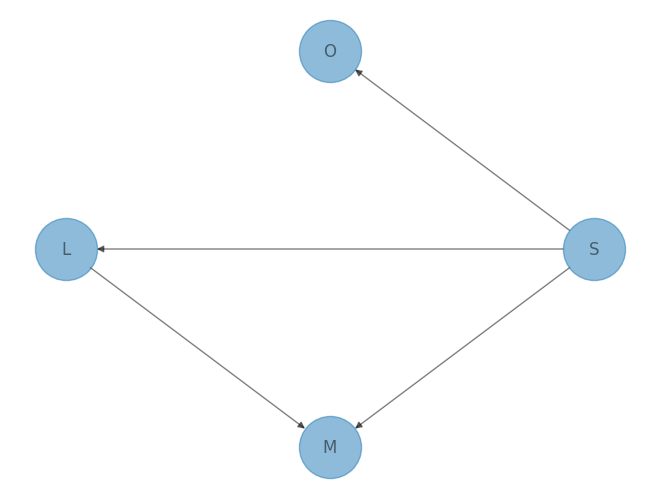

In [ ]:
email_model = DiscreteBayesianNetwork([('S', 'O'), ('S', 'L'), ('S', 'M'), ('L', 'M')])
pos = nx.circular_layout(email_model)
nx.draw(email_model, with_labels=True, pos=pos, alpha=0.5, node_size=2000)

In [ ]:
cpd_s = TabularCPD(variable='S', variable_card=2, values=[[0.6], [0.4]])
print(cpd_s)

cpd_o = TabularCPD(variable='O', variable_card=2, values=[[0.9, 0.3], [0.1, 0.7]],
                   evidence=['S'], evidence_card=[2])
print(cpd_o)

cpd_l = TabularCPD(variable='L', variable_card=2, values=[[0.7, 0.2], [0.3, 0.8]],
                   evidence=['S'], evidence_card=[2])
print(cpd_l)

cpd_m = TabularCPD(variable='M', variable_card=2, values=[[0.8, 0.4, 0.5, 0.1], [0.2, 0.6, 0.5, 0.9]],
                   evidence=['S', 'L'], evidence_card=[2, 2])
print(cpd_m)

email_model.add_cpds(cpd_s, cpd_o, cpd_l, cpd_m)
print(email_model.check_model())

+------+-----+
| S(0) | 0.6 |
+------+-----+
| S(1) | 0.4 |
+------+-----+
+------+------+------+
| S    | S(0) | S(1) |
+------+------+------+
| O(0) | 0.9  | 0.3  |
+------+------+------+
| O(1) | 0.1  | 0.7  |
+------+------+------+
+------+------+------+
| S    | S(0) | S(1) |
+------+------+------+
| L(0) | 0.7  | 0.2  |
+------+------+------+
| L(1) | 0.3  | 0.8  |
+------+------+------+
+------+------+------+------+------+
| S    | S(0) | S(0) | S(1) | S(1) |
+------+------+------+------+------+
| L    | L(0) | L(1) | L(0) | L(1) |
+------+------+------+------+------+
| M(0) | 0.8  | 0.4  | 0.5  | 0.1  |
+------+------+------+------+------+
| M(1) | 0.2  | 0.6  | 0.5  | 0.9  |
+------+------+------+------+------+
True


In [ ]:
print(email_model.local_independencies(['S', 'O', 'L', 'M']))

(L ⟂ O | S)
(M ⟂ O | L, S)
(O ⟂ L, M | S)


In [ ]:
infer = VariableElimination(email_model)
for o, l, m in itertools.product([1, 0], repeat=3):
    p = infer.query(['S'], evidence={'O': o, 'L': l, 'M': m}, show_progress=False)
    p_spam = p.values[1]
    print(o, l, m, round(p_spam, 3), 'spam' if p_spam > 0.5 else 'non-spam')

1 1 1 0.949 spam
1 1 0 0.757 spam
1 0 1 0.769 spam
1 0 0 0.455 non-spam
0 1 1 0.471 non-spam
0 1 0 0.129 non-spam
0 0 1 0.137 non-spam
0 0 0 0.038 non-spam
